<a href="https://colab.research.google.com/github/SantiagoAmaya99/Crack-Detector-Using-Deep-Learning-Models/blob/main/Prueba_de_modelos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#@title Librerias
import tensorflow as tf
import pandas as pd
import numpy as np
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras import layers, models
from sklearn.model_selection import StratifiedGroupKFold
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.applications import ConvNeXtTiny
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
import os, re, shutil
from pathlib import Path
from tqdm.auto import tqdm

In [ ]:
from pathlib import Path

# Busca automáticamente la carpeta base que contiene a 'Decks', 'Pavements' y 'Walls'
try:
    ruta_base = list(Path('/kaggle/input').rglob('Decks'))[0].parent
    RUTA_CRUDO = ruta_base
    print(f"✅ RUTA_CRUDO configurada exitosamente en: {RUTA_CRUDO}")
except IndexError:
    print("❌ No se encontró la carpeta. Verifica que el dataset esté bien adjuntado.")

✅ RUTA_CRUDO configurada exitosamente en: /kaggle/input/datasets/aniruddhsharma/structural-defects-network-concrete-crack-images


In [ ]:
def id_foto(nombre_archivo):
    m = re.search(r'(\d+)[-_]\d+', Path(nombre_archivo).stem)
    return m.group(1) if m else Path(nombre_archivo).stem

registros = []

for material in ['Decks', 'Pavements', 'Walls']:
    for clase, etiqueta in [('Cracked', 1), ('Non-cracked', 0)]:
        carpeta_origen = RUTA_CRUDO / material / clase

        if carpeta_origen.exists():
            archivos = [
                f for f in carpeta_origen.iterdir()
                if f.is_file()
                and f.suffix.lower() in ['.jpg', '.jpeg', '.png']
                and f.stat().st_size > 0
            ]

            for f in tqdm(archivos, desc=f'{material}/{clase}'):
                registros.append({
                    'ruta': str(f),
                    'etiqueta': etiqueta,
                    'grupo': f'{material}_{id_foto(f.name)}'
                })

df = pd.DataFrame(registros)
print(f"Total de imágenes válidas mapeadas: {len(df)}")

Decks/Cracked:   0%|          | 0/2025 [00:00<?, ?it/s]

Decks/Non-cracked:   0%|          | 0/11595 [00:00<?, ?it/s]

Pavements/Cracked:   0%|          | 0/2608 [00:00<?, ?it/s]

Pavements/Non-cracked:   0%|          | 0/21726 [00:00<?, ?it/s]

Walls/Cracked:   0%|          | 0/3851 [00:00<?, ?it/s]

Walls/Non-cracked:   0%|          | 0/14287 [00:00<?, ?it/s]

Total de imágenes válidas mapeadas: 56092


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

seed = 42

def dividir_por_grupo(datos, fraccion, seed):
    gss = GroupShuffleSplit(n_splits=1, test_size=fraccion, random_state=seed)
    idx_a, idx_b = next(gss.split(datos, groups=datos['grupo']))
    return datos.iloc[idx_a].reset_index(drop=True), datos.iloc[idx_b].reset_index(drop=True)

df_trainval, df_test = dividir_por_grupo(df, 0.15, seed)
df_train, df_val = dividir_por_grupo(df_trainval, 0.15 / 0.85, seed)

print(f"Train: {len(df_train)} | Val: {len(df_val)} | Test: {len(df_test)}")

Train: 39046 | Val: 8478 | Test: 8568


In [ ]:
import tensorflow as tf
from tensorflow import keras

seed = 42


TAM_IMG = (128, 128)
TAM_LOTE = 64
AUTOTUNE = tf.data.AUTOTUNE

n_total = len(df_train)
n1 = int(df_train.etiqueta.sum())
n0 = n_total - n1
PESO_CLASE = {0: n_total / (2 * n0), 1: n_total / (2 * n1)}

augment = keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.1, fill_mode='reflect'),
    layers.RandomContrast(0.2),
    layers.RandomBrightness(0.2, value_range=(0, 255)),
])

def cargar_imagen(ruta, etiqueta):
    img = tf.io.read_file(ruta)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, TAM_IMG)
    return img, tf.cast(etiqueta, tf.float32)

def crear_dataset(datos, entrenamiento=False):
    rutas = datos['ruta'].astype(str).values
    etiquetas = datos['etiqueta'].values.astype('int32')
    ds = tf.data.Dataset.from_tensor_slices((rutas, etiquetas))

    if entrenamiento:
        ds = ds.shuffle(len(datos), seed, reshuffle_each_iteration=True)

    ds = ds.map(cargar_imagen, num_parallel_calls=AUTOTUNE)
    ds = ds.map(lambda x, y: (x / 255.0, y), num_parallel_calls=AUTOTUNE)

    if entrenamiento:
        ds = ds.map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=AUTOTUNE)
        w0, w1 = PESO_CLASE[0], PESO_CLASE[1]
        ds = ds.map(lambda x, y: (x, y, tf.where(y > 0.5, w1, w0)), num_parallel_calls=AUTOTUNE)

    return ds.batch(TAM_LOTE).prefetch(AUTOTUNE)

ds_train = crear_dataset(df_train, entrenamiento=True)
ds_val = crear_dataset(df_val)
ds_test = crear_dataset(df_test)

In [ ]:
import tensorflow as tf

def obtener_callbacks(nombre_modelo):

    return [
        tf.keras.callbacks.EarlyStopping(
            monitor='val_auc',
            mode='max',
            patience=8,
            restore_best_weights=True,
            verbose=1
        ),
        tf.keras.callbacks.ModelCheckpoint(
            filepath=f'{nombre_modelo}_feature_extraction.keras',
            monitor='val_auc',
            mode='max',
            save_best_only=True,
            verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=3,
            min_lr=1e-6,
            verbose=1
        )
    ]

#ResNET 50

In [ ]:
def build_resnet50_base(input_shape=(128, 128, 3)):
    base_model = ResNet50(
        weights='imagenet',
        include_top=False,
        input_shape=input_shape
    )
    base_model.trainable = False

    modelResNET = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.4),
        layers.Dense(1, activation='sigmoid')
    ])

    return modelResNET, base_model

modelResNET, base_model_resnet = build_resnet50_base()

modelResNET.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

history_resnet = modelResNET.fit(
    ds_train,
    validation_data=ds_val,
    epochs=20,
    callbacks=obtener_callbacks('resnet50')
)

Epoch 1/20
611/611 ━━━━━━━━━━━━━━━━━━━━ 0s 218ms/step - accuracy: 0.3959 - auc: 0.4873 - loss: 0.6975
Epoch 1: val_auc improved from None to 0.46642, saving model to resnet50_feature_extraction.keras

Epoch 1: finished saving model to resnet50_feature_extraction.keras
611/611 ━━━━━━━━━━━━━━━━━━━━ 165s 253ms/step - accuracy: 0.4453 - auc: 0.4921 - loss: 0.6984 - val_accuracy: 0.8390 - val_auc: 0.4664 - val_loss: 0.6853 - learning_rate: 1.0000e-04
Epoch 2/20
610/611 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step - accuracy: 0.4865 - auc: 0.5026 - loss: 0.7001
Epoch 2: val_auc improved from 0.46642 to 0.48241, saving model to resnet50_feature_extraction.keras

Epoch 2: finished saving model to resnet50_feature_extraction.keras
611/611 ━━━━━━━━━━━━━━━━━━━━ 101s 164ms/step - accuracy: 0.5059 - auc: 0.5013 - loss: 0.6952 - val_accuracy: 0.2029 - val_auc: 0.4824 - val_loss: 0.6989 - learning_rate: 1.0000e-04
Epoch 3/20
610/611 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step - accuracy: 0.4321 - auc: 0.4975 - loss: 0.

#EfficientNetB0

In [ ]:
def build_efficientnet_base(input_shape=(128, 128, 3)):
    base_model = EfficientNetB0(
        weights='imagenet',
        include_top=False,
        input_shape=input_shape
    )
    base_model.trainable = False

    model_efficient = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.4),
        layers.Dense(1, activation='sigmoid')
    ])

    return model_efficient, base_model

model_efficient, base_model_efficient = build_efficientnet_base()

model_efficient.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

history_efficientnet = model_efficient.fit(
    ds_train,
    validation_data=ds_val,
    epochs=20,
    callbacks=obtener_callbacks('efficientnet_b0')
)

Epoch 1/20


E0000 00:00:1793817609.214934     117 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793817609.379481     117 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793817613.260630     117 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793817613.441749     117 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


610/611 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step - accuracy: 0.5505 - auc: 0.5068 - loss: 0.6989

E0000 00:00:1793817703.493737     116 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793817703.684155     116 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793817705.234274     116 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793817705.385713     116 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


611/611 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step - accuracy: 0.5504 - auc: 0.5068 - loss: 0.6989

E0000 00:00:1793817724.328053     115 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793817724.482199     115 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793817725.307541     115 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793817725.483979     115 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.



Epoch 1: val_auc improved from None to 0.50000, saving model to efficientnet_b0_feature_extraction.keras

Epoch 1: finished saving model to efficientnet_b0_feature_extraction.keras
611/611 ━━━━━━━━━━━━━━━━━━━━ 135s 176ms/step - accuracy: 0.5177 - auc: 0.5052 - loss: 0.7000 - val_accuracy: 0.1608 - val_auc: 0.5000 - val_loss: 0.7124 - learning_rate: 1.0000e-04
Epoch 2/20
610/611 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - accuracy: 0.4842 - auc: 0.4998 - loss: 0.7015
Epoch 2: val_auc did not improve from 0.50000
611/611 ━━━━━━━━━━━━━━━━━━━━ 81s 133ms/step - accuracy: 0.4943 - auc: 0.5049 - loss: 0.6998 - val_accuracy: 0.8392 - val_auc: 0.5000 - val_loss: 0.6795 - learning_rate: 1.0000e-04
Epoch 3/20
610/611 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - accuracy: 0.5421 - auc: 0.5060 - loss: 0.6918
Epoch 3: val_auc improved from 0.50000 to 0.50952, saving model to efficientnet_b0_feature_extraction.keras

Epoch 3: finished saving model to efficientnet_b0_feature_extraction.keras
611/611 ━━━━━━━━━━━━━━━

#VGG16

In [ ]:
def build_vgg16_base(input_shape=(128, 128, 3)):
    base_vgg = VGG16(
        weights='imagenet',
        include_top=False,
        input_shape=input_shape
    )
    base_vgg.trainable = False

    model_vgg = models.Sequential([
        base_vgg,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.4),
        layers.Dense(1, activation='sigmoid')
    ])

    return model_vgg, base_vgg

model_vgg, base_vgg = build_vgg16_base()

model_vgg.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

history_vgg = model_vgg.fit(
    ds_train,
    validation_data=ds_val,
    epochs=20,
    callbacks=obtener_callbacks('vgg16')
)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/20
611/611 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step - accuracy: 0.3729 - auc: 0.5007 - loss: 0.7604
Epoch 1: val_auc improved from None to 0.50657, saving model to vgg16_feature_extraction.keras

Epoch 1: finished saving model to vgg16_feature_extraction.keras
611/611 ━━━━━━━━━━━━━━━━━━━━ 129s 202ms/step - accuracy: 0.4320 - auc: 0.5031 - loss: 0.7383 - val_accuracy: 0.6706 - val_auc: 0.5066 - val_loss: 0.6673 - learning_rate: 1.0000e-04
Epoch 2/20
610/611 ━━━━━━━━━━━━━━━━━━━━ 0s 174ms/step - accuracy: 0.5087 - auc: 0.5041 - loss: 0.7108
Epoch 2: val_auc improved from 0.50657 to 0.58145, saving model to vgg16_feature_extraction.keras

Epoch 2: finished saving model to vgg16_feature_extraction.keras
611/611 ━━━━━━━━━━━━━━━━━━━━ 119s 194ms/step - accuracy: 0.5113 - auc: 0.5026 - loss: 0.7117 - val_accuracy: 0.6122 - val_auc: 0.5815 - val_loss: 0.6776 - learning_rate: 1.0000e-04
Epoch 3/20
610/611 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step - ac

#DenseNet121

In [ ]:
# 1. Base y arquitectura
base_dense = DenseNet121(weights='imagenet', include_top=False, input_shape=(128, 128, 3))

base_dense.trainable = False

model_dense = models.Sequential([
    base_dense,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.4),
    layers.Dense(1, activation='sigmoid')
])

# 3. Compilación (LR = 1e-4)
model_dense.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

model_dense.summary()


29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ densenet121 (Functional)        │ (None, 4, 4, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │         1,025 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,038,529 (26.85 MB)

 Trainable params: 1,025 (4.00 KB)

 Non-trainable params: 7,037,504 (26.85 MB)

In [ ]:
history_dense = model_dense.fit(
    ds_train,
    validation_data=ds_val,
    epochs=20,
    callbacks=obtener_callbacks('densenet121')
)

Epoch 1/20
611/611 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step - accuracy: 0.4766 - auc: 0.4984 - loss: 0.7453
Epoch 1: val_auc improved from None to 0.49643, saving model to densenet121_feature_extraction.keras

Epoch 1: finished saving model to densenet121_feature_extraction.keras
611/611 ━━━━━━━━━━━━━━━━━━━━ 159s 216ms/step - accuracy: 0.4993 - auc: 0.5009 - loss: 0.7336 - val_accuracy: 0.4049 - val_auc: 0.4964 - val_loss: 0.7528 - learning_rate: 1.0000e-04
Epoch 2/20
610/611 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step - accuracy: 0.5068 - auc: 0.4952 - loss: 0.7180
Epoch 2: val_auc improved from 0.49643 to 0.58544, saving model to densenet121_feature_extraction.keras

Epoch 2: finished saving model to densenet121_feature_extraction.keras
611/611 ━━━━━━━━━━━━━━━━━━━━ 97s 158ms/step - accuracy: 0.5077 - auc: 0.5027 - loss: 0.7149 - val_accuracy: 0.3553 - val_auc: 0.5854 - val_loss: 0.7762 - learning_rate: 1.0000e-04
Epoch 3/20
610/611 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step - accuracy: 0.5224 - auc: 0.5084

#ConvNeXt

In [ ]:
base_convnext = ConvNeXtTiny(weights='imagenet', include_top=False, input_shape=(128, 128, 3))
base_convnext.trainable = False

model_convnext = models.Sequential([
    base_convnext,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.4),
    layers.Dense(1, activation='sigmoid')
])

model_convnext.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

history_convnext = model_convnext.fit(
    ds_train,
    validation_data=ds_val,
    epochs=20,
    callbacks=obtener_callbacks('convnext_tiny')
)

111650432/111650432 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Epoch 1/20
611/611 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step - accuracy: 0.3935 - auc: 0.4998 - loss: 0.8590
Epoch 1: val_auc improved from None to 0.62232, saving model to convnext_tiny_feature_extraction.keras

Epoch 1: finished saving model to convnext_tiny_feature_extraction.keras
611/611 ━━━━━━━━━━━━━━━━━━━━ 152s 220ms/step - accuracy: 0.4645 - auc: 0.5002 - loss: 0.7864 - val_accuracy: 0.8393 - val_auc: 0.6223 - val_loss: 0.6793 - learning_rate: 1.0000e-04
Epoch 2/20
610/611 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step - accuracy: 0.5138 - auc: 0.5056 - loss: 0.7174
Epoch 2: val_auc improved from 0.62232 to 0.63446, saving model to convnext_tiny_feature_extraction.keras

Epoch 2: finished saving model to convnext_tiny_feature_extraction.keras
611/611 ━━━━━━━━━━━━━━━━━━━━ 118s 192ms/step - accuracy: 0.5133 - auc: 0.5073 - loss: 0.7169 - val_accuracy: 0.5553 - val_auc: 0.6345 - val_loss: 0.6886 - learning_rate: 1.0000e-04
Epoch 3/20
610/611 ━━━━━

#MobileNetV2

In [ ]:
def build_mobilenetv2_base(input_shape=(128, 128, 3)):
    base_mobilenet = MobileNetV2(
        weights='imagenet',
        include_top=False,
        input_shape=input_shape
    )
    base_mobilenet.trainable = False

    model_mobilenet = models.Sequential([
        base_mobilenet,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.4),
        layers.Dense(1, activation='sigmoid')
    ])

    return model_mobilenet, base_mobilenet

model_mobilenet, base_mobilenet = build_mobilenetv2_base()

model_mobilenet.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

history_mobilenet = model_mobilenet.fit(
    ds_train,
    validation_data=ds_val,
    epochs=20,
    callbacks=obtener_callbacks('mobilenetv2')
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/20
611/611 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step - accuracy: 0.4916 - auc: 0.4932 - loss: 0.7794
Epoch 1: val_auc improved from None to 0.68358, saving model to mobilenetv2_feature_extraction.keras

Epoch 1: finished saving model to mobilenetv2_feature_extraction.keras
611/611 ━━━━━━━━━━━━━━━━━━━━ 99s 146ms/step - accuracy: 0.4984 - auc: 0.4998 - loss: 0.7716 - val_accuracy: 0.6305 - val_auc: 0.6836 - val_loss: 0.6463 - learning_rate: 1.0000e-04
Epoch 2/20
610/611 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - accuracy: 0.5089 - auc: 0.4977 - loss: 0.7482
Epoch 2: val_auc improved from 0.68358 to 0.71468, saving model to mobilenetv2_feature_extraction.keras

Epoch 2: finished saving model to mobilenetv2_feature_extraction.keras
611/611 ━━━━━━━━━━━━━━━━━━━━ 78s 128ms/step - accuracy: 0.5022 - auc: 0.4999 - loss: 0.7509 - val_accuracy: 0.6511 - val_auc: 0.7147 - val_loss: 0.6423 - learning_rate: 1.0000e-04
Epoch 3/20
610/611 ━━━━━━━━━━━━━━━━━━━

Extrayendo etiquetas reales de ds_test...
--- Evaluando ResNet50 ---
--- Evaluando EfficientNetB0 ---
--- Evaluando VGG16 ---
--- Evaluando DenseNet121 ---
--- Evaluando ConvNeXtTiny ---
--- Evaluando MobileNetV2 ---


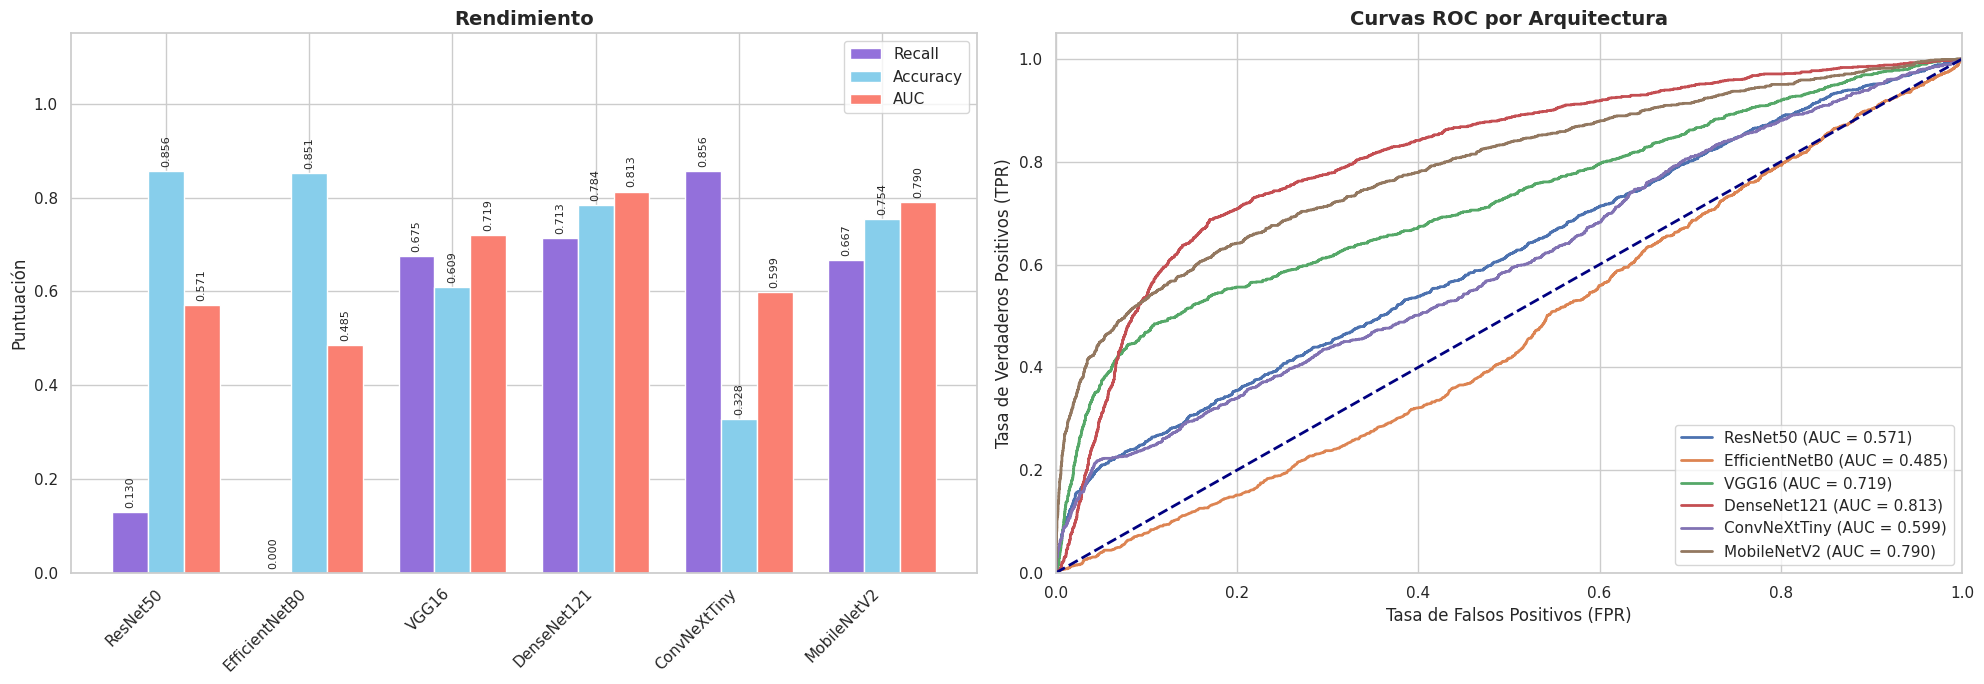

In [ ]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc, recall_score, confusion_matrix

# 1. Definir los nombres exactos de los archivos guardados
modelos_archivos = {
    'ResNet50': 'resnet50_feature_extraction.keras',
    'EfficientNetB0': 'efficientnet_b0_feature_extraction.keras',
    'VGG16': 'vgg16_feature_extraction.keras',
    'DenseNet121': 'densenet121_feature_extraction.keras',
    'ConvNeXtTiny': 'convnext_tiny_feature_extraction.keras',
    'MobileNetV2': 'mobilenetv2_feature_extraction.keras'
}

# 2. Extraer las etiquetas reales del dataset de prueba
print("Extrayendo etiquetas reales de ds_test...")
y_true = np.concatenate([y.numpy() for x, y in ds_test], axis=0)

resultados = {}
curvas_roc = {}

# 3. Evaluar cada modelo iterativamente
for nombre, archivo in modelos_archivos.items():
    if not os.path.exists(archivo):
        print(f"⚠️ Archivo no encontrado: {archivo}. Saltando {nombre}...")
        continue

    print(f"--- Evaluando {nombre} ---")

    # Cargar el modelo preentrenado
    modelo = tf.keras.models.load_model(archivo)

    # Evaluar con ds_test para obtener loss, accuracy y auc
    metricas = modelo.evaluate(ds_test, verbose=0)
    test_loss, test_acc, test_auc = metricas[0], metricas[1], metricas[2]

    # Generar predicciones probabilísticas
    y_pred_prob = modelo.predict(ds_test, verbose=0).ravel()

    # Convertir probabilidades a clases binarias (umbral 0.5) para calcular el Recall
    y_pred_bin = (y_pred_prob > 0.5).astype(int)
    test_recall = recall_score(y_true, y_pred_bin)

    # Calcular datos de la curva ROC
    fpr, tpr, umbrales = roc_curve(y_true, y_pred_prob)

    # Guardar los 3 resultados clave
    resultados[nombre] = {'Recall': test_recall, 'Accuracy': test_acc, 'AUC': test_auc}
    curvas_roc[nombre] = (fpr, tpr, test_auc)

# 4. GRAFICAR RESULTADOS

# Configuración de estilo
sns.set_theme(style="whitegrid")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 7)) # Ligeramente más ancho para acomodar las 3 barras

# --- Gráfico 1: Comparativa de Recall, Accuracy y AUC (Barras) ---
nombres = list(resultados.keys())
recall_scores = [resultados[n]['Recall'] for n in nombres]
acc_scores = [resultados[n]['Accuracy'] for n in nombres]
auc_scores = [resultados[n]['AUC'] for n in nombres]

x = np.arange(len(nombres))
width = 0.25 # Reducido a 0.25 para que quepan 3 barras

# Crear las 3 barras desplazándolas en el eje X
rects1 = ax1.bar(x - width, recall_scores, width, label='Recall', color='mediumpurple')
rects2 = ax1.bar(x, acc_scores, width, label='Accuracy', color='skyblue')
rects3 = ax1.bar(x + width, auc_scores, width, label='AUC', color='salmon')

ax1.set_ylabel('Puntuación')
ax1.set_title('Rendimiento', fontsize=14, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(nombres, rotation=45, ha='right')
ax1.legend()
ax1.set_ylim(0, 1.15) # Un poco más alto para las etiquetas

# Agregar etiquetas de valor sobre las 3 barras
for rects in [rects1, rects2, rects3]:
    for rect in rects:
        height = rect.get_height()
        ax1.annotate(f'{height:.3f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=8, rotation=90) # Texto rotado 90 grados para que no se pisen

# --- Gráfico 2: Curvas ROC ---
for nombre, (fpr, tpr, roc_auc) in curvas_roc.items():
    ax2.plot(fpr, tpr, lw=2, label=f'{nombre} (AUC = {roc_auc:.3f})')

ax2.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
ax2.set_xlim([0.0, 1.0])
ax2.set_ylim([0.0, 1.05])
ax2.set_xlabel('Tasa de Falsos Positivos (FPR)')
ax2.set_ylabel('Tasa de Verdaderos Positivos (TPR)')
ax2.set_title('Curvas ROC por Arquitectura', fontsize=14, fontweight='bold')
ax2.legend(loc="lower right")

plt.tight_layout()
plt.savefig('comparativa_recall_acc_auc.png', dpi=300, bbox_inches='tight')
plt.show()